# Realistic Human Face Generation using GAN

**Objective:** develop a Generative Adversarial Network (DCGAN) that generates realistic synthetic human face images from random noise.

**Project steps**
1. Load and preprocess a human face dataset (crop, resize, normalize)
2. Build the Generator and Discriminator models
3. Combine them into a GAN and train using random latent vectors
4. Monitor losses and save generated samples during training
5. Compare results over time and present the final generated faces

> Tip: run this notebook on a GPU (Kaggle: `Settings > Accelerator > GPU`, Colab: `Runtime > Change runtime type > T4 GPU`).

## 1. Setup

In [1]:
import os, glob, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.utils as vutils

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Configuration
Reduce `MAX_IMAGES` (e.g. `20000`) and `EPOCHS` (e.g. `10`) for a quick test run.

In [2]:
IMAGE_SIZE  = 64        # output resolution (64x64)
BATCH_SIZE  = 128
EPOCHS      = 30
NZ          = 100       # size of the latent vector
LR          = 2e-4
BETA1       = 0.5
MAX_IMAGES  = 0         # 0 = use the whole dataset
NUM_WORKERS = 2

NC, NGF, NDF = 3, 64, 64   # channels, generator/discriminator feature-map sizes

OUT_DIR = "output"
os.makedirs(f"{OUT_DIR}/samples", exist_ok=True)

## 3. Load the dataset
We use the **CelebA** face dataset.


In [3]:
ON_KAGGLE = os.path.exists("/kaggle/input")
DATA_DIR = "/kaggle/input" if ON_KAGGLE else "data"   # change if running elsewhere

image_paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
if MAX_IMAGES:
    image_paths = image_paths[:MAX_IMAGES]
print("Running on Kaggle:", ON_KAGGLE)
print("Dataset folder:", DATA_DIR)
print("Number of images:", len(image_paths))
assert len(image_paths) > 0, "No images found - add the CelebA dataset (or fix DATA_DIR)"

Running on Kaggle: True
Dataset folder: /kaggle/input
Number of images: 202599


## 4. Preprocessing
- **Crop:** center crop to remove the background around the face
- **Resize:** scale to 64x64
- **Normalize:** scale pixel values to `[-1, 1]` to match the Generator's `Tanh` output

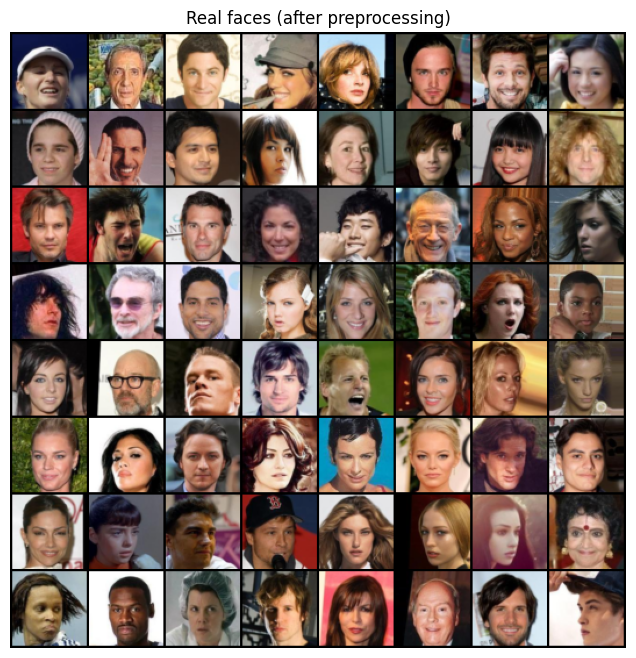

In [4]:
transform = T.Compose([
    T.CenterCrop(160),
    T.Resize(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

class FaceDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = paths, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(img)

dataset = FaceDataset(image_paths, transform)
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=NUM_WORKERS, drop_last=True, pin_memory=True)

def show_grid(tensor, title="", nrow=8, figsize=(8, 8)):
    grid = vutils.make_grid(tensor, nrow=nrow, padding=2, normalize=True)
    plt.figure(figsize=figsize)
    plt.imshow(grid.permute(1, 2, 0).cpu())
    plt.axis("off"); plt.title(title)
    plt.show()

real_batch = next(iter(loader))
show_grid(real_batch[:64], "Real faces (after preprocessing)")
vutils.save_image(real_batch[:64], f"{OUT_DIR}/real_faces.png", normalize=True, nrow=8)

## 5. Build the models

**Generator:** random vector `(100, 1, 1)` -> RGB image `(3, 64, 64)` using transposed convolutions.

**Discriminator:** image `(3, 64, 64)` -> probability that the image is real.

In [5]:
def weights_init(m):
    name = m.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(NZ, NGF * 8, 4, 1, 0, bias=False),       # 4x4
            nn.BatchNorm2d(NGF * 8), nn.ReLU(True),
            nn.ConvTranspose2d(NGF * 8, NGF * 4, 4, 2, 1, bias=False),  # 8x8
            nn.BatchNorm2d(NGF * 4), nn.ReLU(True),
            nn.ConvTranspose2d(NGF * 4, NGF * 2, 4, 2, 1, bias=False),  # 16x16
            nn.BatchNorm2d(NGF * 2), nn.ReLU(True),
            nn.ConvTranspose2d(NGF * 2, NGF, 4, 2, 1, bias=False),      # 32x32
            nn.BatchNorm2d(NGF), nn.ReLU(True),
            nn.ConvTranspose2d(NGF, NC, 4, 2, 1, bias=False),           # 64x64
            nn.Tanh(),
        )
    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(NC, NDF, 4, 2, 1, bias=False),                    # 32x32
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(NDF, NDF * 2, 4, 2, 1, bias=False),               # 16x16
            nn.BatchNorm2d(NDF * 2), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(NDF * 2, NDF * 4, 4, 2, 1, bias=False),           # 8x8
            nn.BatchNorm2d(NDF * 4), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(NDF * 4, NDF * 8, 4, 2, 1, bias=False),           # 4x4
            nn.BatchNorm2d(NDF * 8), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(NDF * 8, 1, 4, 1, 0, bias=False),                 # 1x1
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x).view(-1)


netG = Generator().to(device); netG.apply(weights_init)
netD = Discriminator().to(device); netD.apply(weights_init)

print(netG)
print(netD)
print(f"Generator params:     {sum(p.numel() for p in netG.parameters()):,}")
print(f"Discriminator params: {sum(p.numel() for p in netD.parameters()):,}")

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
  )
)
D

## 6. Combine into a GAN and train

Both networks play a minimax game:
- **Discriminator** maximizes `log D(x) + log(1 - D(G(z)))`
- **Generator** maximizes `log D(G(z))`

We use label smoothing (real label = 0.9) to stabilize training, and a **fixed noise** batch so we can compare the Generator's output across epochs.

In [6]:
criterion = nn.BCELoss()
optD = torch.optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optG = torch.optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

fixed_noise = torch.randn(64, NZ, 1, 1, device=device)

G_losses, D_losses = [], []
D_real_scores, D_fake_scores = [], []
epoch_samples = {}   # epoch -> generated grid (for comparison over time)

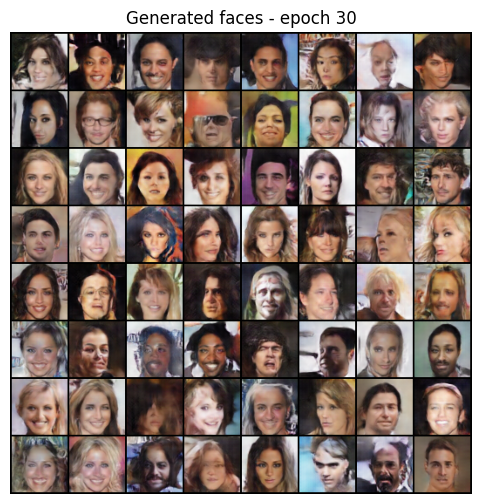

Training finished.


In [7]:
from IPython.display import clear_output

for epoch in range(1, EPOCHS + 1):
    for i, real in enumerate(loader):
        real = real.to(device)
        b = real.size(0)
        real_label = torch.full((b,), 0.9, device=device)
        fake_label = torch.zeros(b, device=device)

        # ---- 1) Train Discriminator
        netD.zero_grad()
        out_real = netD(real)
        loss_real = criterion(out_real, real_label)

        noise = torch.randn(b, NZ, 1, 1, device=device)
        fake = netG(noise)
        out_fake = netD(fake.detach())
        loss_fake = criterion(out_fake, fake_label)

        lossD = loss_real + loss_fake
        lossD.backward()
        optD.step()

        # ---- 2) Train Generator
        netG.zero_grad()
        lossG = criterion(netD(fake), torch.ones(b, device=device))
        lossG.backward()
        optG.step()

        # ---- Monitor
        G_losses.append(lossG.item()); D_losses.append(lossD.item())
        D_real_scores.append(out_real.mean().item())
        D_fake_scores.append(out_fake.mean().item())

        if i % 100 == 0:
            print(f"[{epoch}/{EPOCHS}][{i}/{len(loader)}] "
                  f"Loss_D: {lossD.item():.3f}  Loss_G: {lossG.item():.3f}  "
                  f"D(x): {D_real_scores[-1]:.3f}  D(G(z)): {D_fake_scores[-1]:.3f}")

    # ---- Save generated samples every epoch
    netG.eval()
    with torch.no_grad():
        samples = netG(fixed_noise).cpu()
    netG.train()
    vutils.save_image(samples, f"{OUT_DIR}/samples/epoch_{epoch:03d}.png", normalize=True, nrow=8)
    epoch_samples[epoch] = vutils.make_grid(samples, padding=2, normalize=True, nrow=8)

    if epoch % 5 == 0 or epoch == 1:
        clear_output(wait=True)
        show_grid(samples, f"Generated faces - epoch {epoch}", figsize=(6, 6))

    torch.save(netG.state_dict(), f"{OUT_DIR}/generator.pth")
    torch.save(netD.state_dict(), f"{OUT_DIR}/discriminator.pth")

print("Training finished.")

## 7. Monitor losses

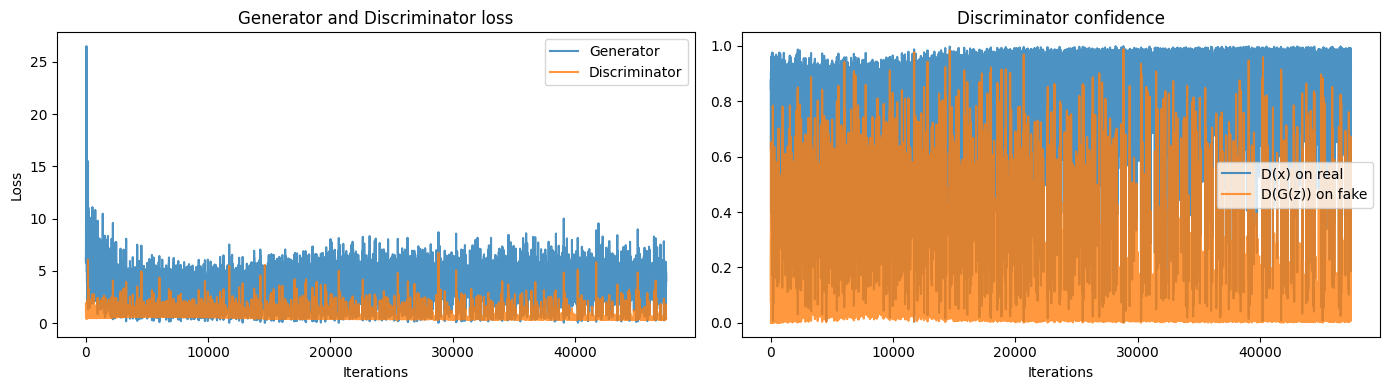

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(G_losses, label="Generator", alpha=0.8)
axes[0].plot(D_losses, label="Discriminator", alpha=0.8)
axes[0].set_title("Generator and Discriminator loss")
axes[0].set_xlabel("Iterations"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(D_real_scores, label="D(x) on real", alpha=0.8)
axes[1].plot(D_fake_scores, label="D(G(z)) on fake", alpha=0.8)
axes[1].set_title("Discriminator confidence")
axes[1].set_xlabel("Iterations"); axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/loss_curves.png", dpi=150)
plt.show()

## 8. Compare results over time

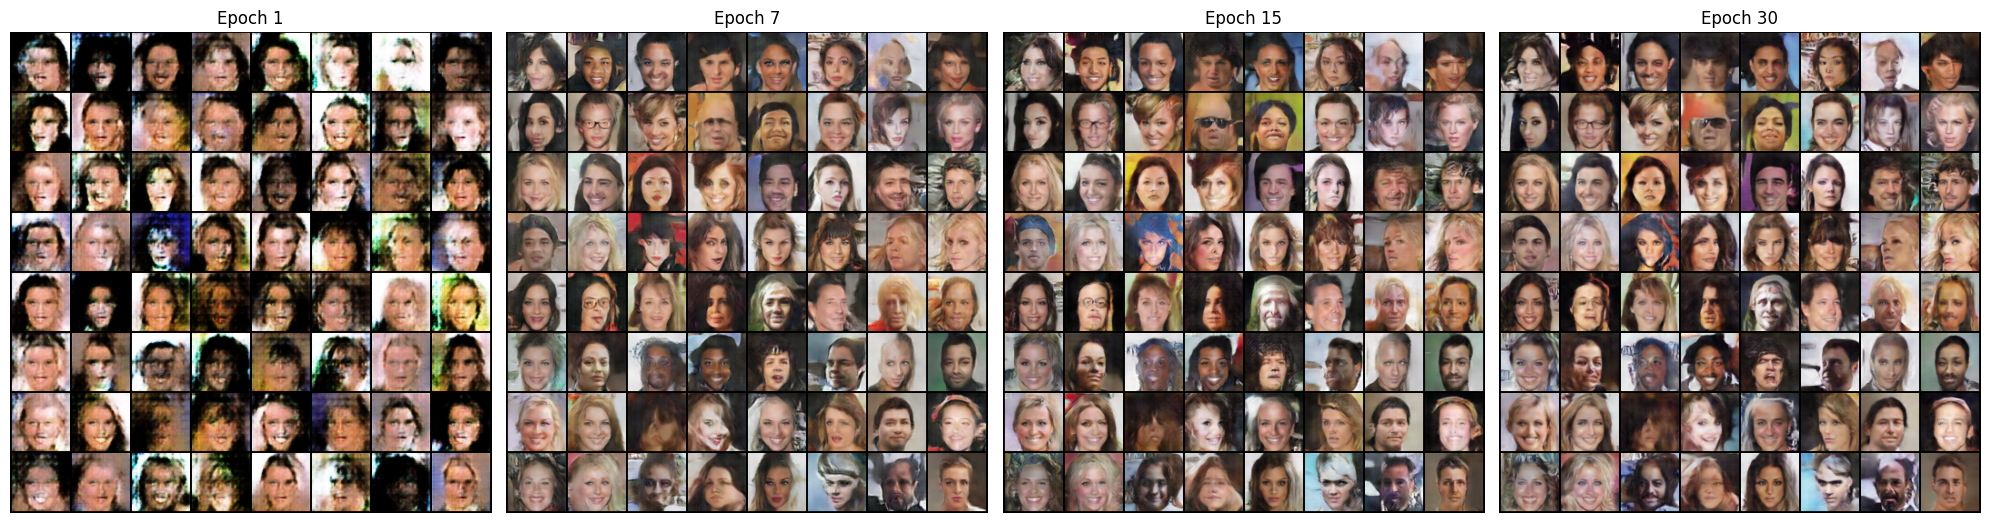

In [9]:
epochs_to_show = sorted(set([1, max(1, EPOCHS // 4), max(1, EPOCHS // 2), EPOCHS]))

fig, axes = plt.subplots(1, len(epochs_to_show), figsize=(5 * len(epochs_to_show), 5.5))
axes = np.atleast_1d(axes)
for ax, ep in zip(axes, epochs_to_show):
    ax.imshow(epoch_samples[ep].permute(1, 2, 0))
    ax.set_title(f"Epoch {ep}"); ax.axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/progress_comparison.png", dpi=150)
plt.show()

In [10]:
# Animated GIF of the training progress (same noise, every epoch)
frames = []
for ep in sorted(epoch_samples):
    arr = (epoch_samples[ep].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    frames.append(Image.fromarray(arr))
frames[0].save(f"{OUT_DIR}/training_progress.gif", save_all=True,
               append_images=frames[1:], duration=400, loop=0)
print("Saved", f"{OUT_DIR}/training_progress.gif")

Saved output/training_progress.gif


## 9. Final generated faces

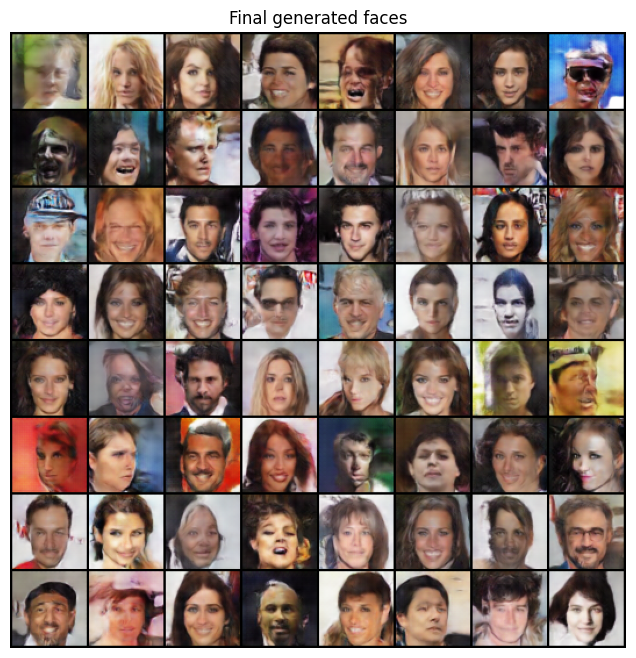

In [11]:
netG.eval()
with torch.no_grad():
    final_faces = netG(torch.randn(64, NZ, 1, 1, device=device)).cpu()
show_grid(final_faces, "Final generated faces")
vutils.save_image(final_faces, f"{OUT_DIR}/final_generated_faces.png", normalize=True, nrow=8)

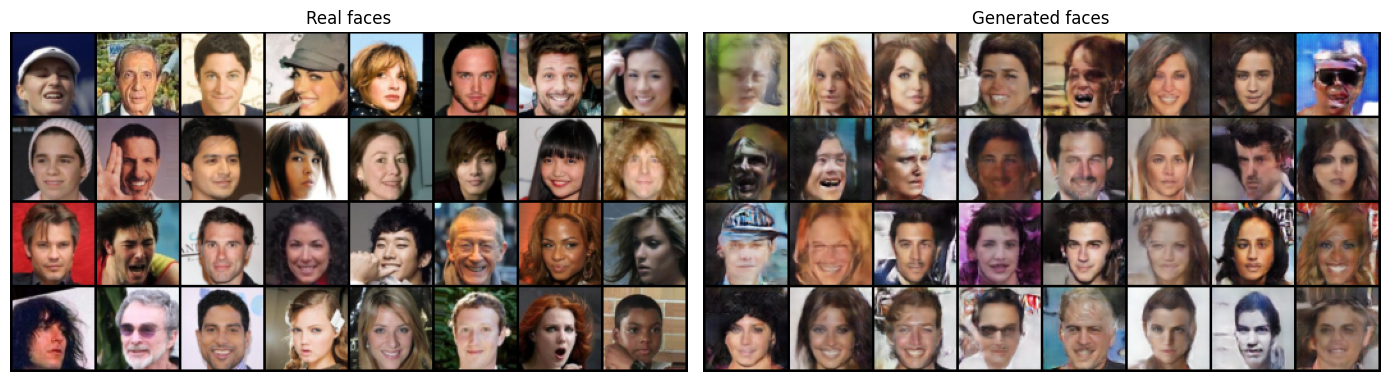

In [12]:
# Real vs generated, side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(vutils.make_grid(real_batch[:32], nrow=8, padding=2, normalize=True).permute(1, 2, 0))
axes[0].set_title("Real faces"); axes[0].axis("off")
axes[1].imshow(vutils.make_grid(final_faces[:32], nrow=8, padding=2, normalize=True).permute(1, 2, 0))
axes[1].set_title("Generated faces"); axes[1].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/real_vs_generated.png", dpi=150)
plt.show()

## 10. Bonus: latent space interpolation
Smoothly morphing between two random faces shows the Generator learned a meaningful latent space.

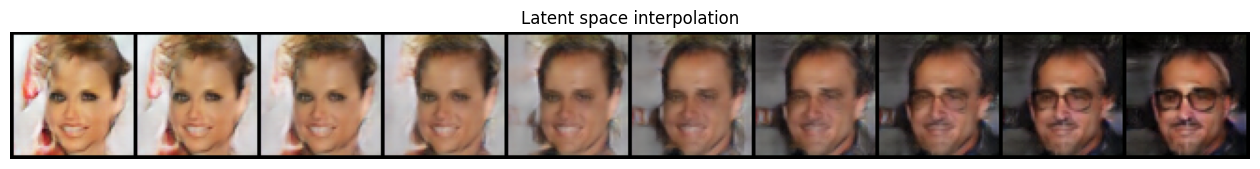

In [13]:
z1 = torch.randn(1, NZ, 1, 1, device=device)
z2 = torch.randn(1, NZ, 1, 1, device=device)
steps = 10
zs = torch.cat([(1 - a) * z1 + a * z2 for a in torch.linspace(0, 1, steps)], dim=0)

with torch.no_grad():
    interp = netG(zs).cpu()
show_grid(interp, "Latent space interpolation", nrow=steps, figsize=(16, 3))
vutils.save_image(interp, f"{OUT_DIR}/interpolation.png", normalize=True, nrow=steps)

## 11. Conclusion
- A DCGAN was trained to generate 64x64 human faces from random noise.
- Early epochs produce blurry blobs; later epochs show clear face structure (eyes, nose, mouth, hair).
- Loss curves show the adversarial balance between Generator and Discriminator.

**Possible improvements:** train longer, use higher resolution (128x128), try WGAN-GP or StyleGAN, and add FID score evaluation.